<a href="https://colab.research.google.com/github/mahithamodepalli29/Retail_Sales_Analysis_/blob/main/Retail_Sales_Analysis_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

df = pd.read_csv("/content/retail_sales_dataset.csv.csv")

print("Shape:", df.shape)
print("\nColumn types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.head()

Shape: (1000, 9)

Column types:
 Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

Missing values:
 Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate rows: 0


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [ ]:
# 1. Convert Date from text to real date
df["Date"] = pd.to_datetime(df["Date"])

# 2. Add helpful new columns (we will use them later)
df["Month"] = df["Date"].dt.month
df["Quarter"] = df["Date"].dt.quarter
df["Month_Name"] = df["Date"].dt.month_name()

# 3. Descriptive statistics
numeric_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]

print("=== Summary Statistics ===")
print(df[numeric_cols].describe())

print("\n=== Mean ===")
print(df[numeric_cols].mean())

print("\n=== Median ===")
print(df[numeric_cols].median())

print("\n=== Mode ===")
print(df[numeric_cols].mode().iloc[0])

print("\n=== Standard Deviation ===")
print(df[numeric_cols].std())

=== Summary Statistics ===
              Age     Quantity  Price per Unit  Total Amount
count  1000.00000  1000.000000     1000.000000   1000.000000
mean     41.39200     2.514000      179.890000    456.000000
std      13.68143     1.132734      189.681356    559.997632
min      18.00000     1.000000       25.000000     25.000000
25%      29.00000     1.000000       30.000000     60.000000
50%      42.00000     3.000000       50.000000    135.000000
75%      53.00000     4.000000      300.000000    900.000000
max      64.00000     4.000000      500.000000   2000.000000

=== Mean ===
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64

=== Median ===
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

=== Mode ===
Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64

=== Standard Deviation ===
Age   

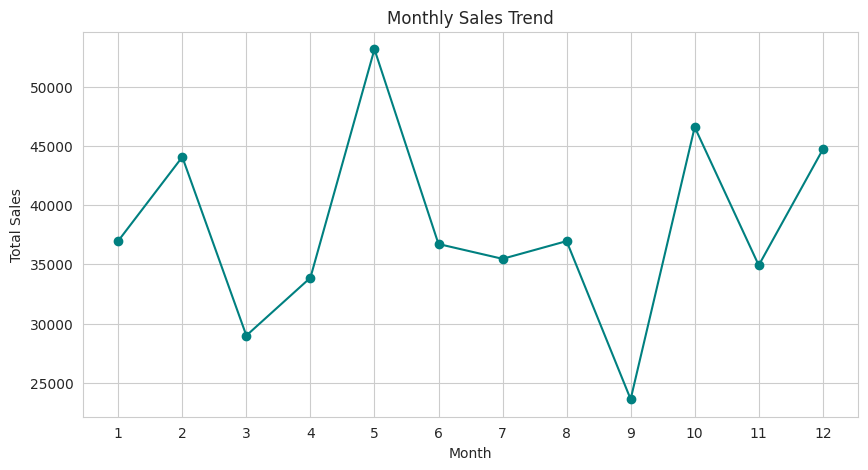

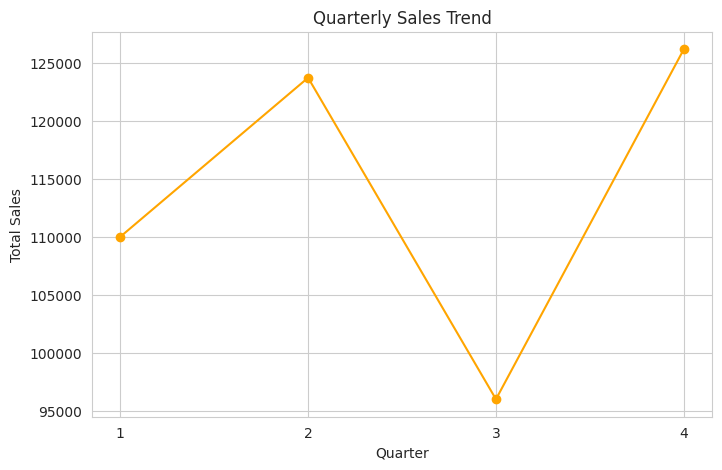

Month
1     36980
2     44060
3     28990
4     33870
5     53150
6     36715
7     35465
8     36960
9     23620
10    46580
11    34920
12    44690
Name: Total Amount, dtype: int64
Quarter
1    110030
2    123735
3     96045
4    126190
Name: Total Amount, dtype: int64


In [ ]:
# Monthly sales
monthly_sales = df.groupby("Month")["Total Amount"].sum()

plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o", color="teal")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(range(1, 13))
plt.show()

# Quarterly sales
quarterly_sales = df.groupby("Quarter")["Total Amount"].sum()

plt.figure(figsize=(8, 5))
plt.plot(quarterly_sales.index, quarterly_sales.values, marker="o", color="orange")
plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks([1, 2, 3, 4])
plt.show()

print(monthly_sales)
print(quarterly_sales)

/tmp/ipykernel_539/1766327273.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Age Group", data=df, palette="viridis")


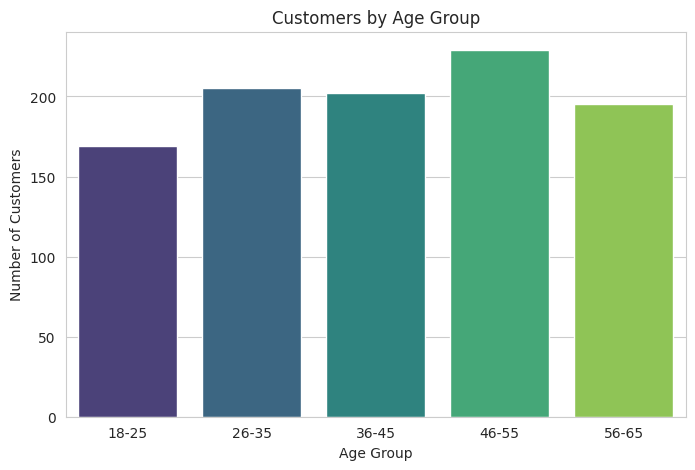

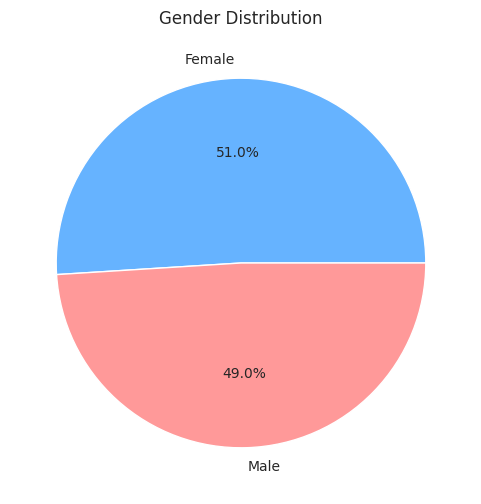

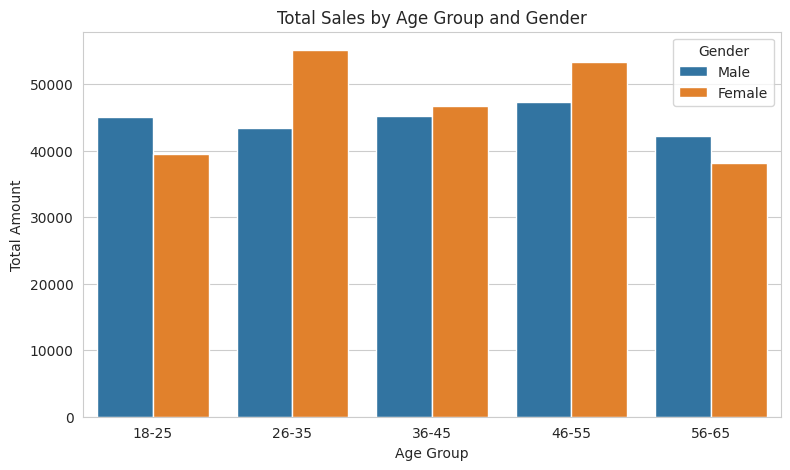

Age Group
18-25    169
26-35    205
36-45    202
46-55    229
56-65    195
Name: count, dtype: int64
Gender
Female    510
Male      490
Name: count, dtype: int64


In [ ]:
# Create age groups
bins = [17, 25, 35, 45, 55, 65]
labels = ["18-25", "26-35", "36-45", "46-55", "56-65"]
df["Age Group"] = pd.cut(df["Age"], bins=bins, labels=labels)

# 1. Age group distribution
plt.figure(figsize=(8, 5))
sns.countplot(x="Age Group", data=df, palette="viridis")
plt.title("Customers by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.show()

# 2. Gender breakdown
plt.figure(figsize=(6, 6))
df["Gender"].value_counts().plot(kind="pie", autopct="%1.1f%%", colors=["#66b3ff", "#ff9999"])
plt.title("Gender Distribution")
plt.ylabel("")
plt.show()

# 3. Sales by gender and age group
plt.figure(figsize=(9, 5))
sns.barplot(x="Age Group", y="Total Amount", hue="Gender", data=df, estimator=sum, errorbar=None)
plt.title("Total Sales by Age Group and Gender")
plt.show()

print(df["Age Group"].value_counts().sort_index())
print(df["Gender"].value_counts())

/tmp/ipykernel_539/2680558815.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_revenue.index, y=category_revenue.values, palette="Set2")


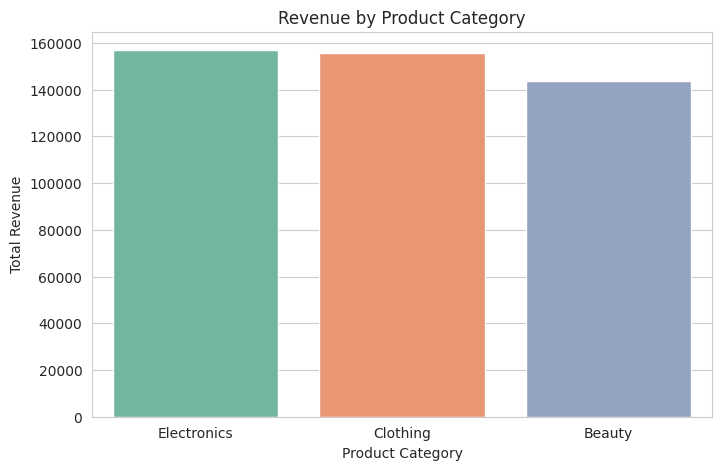

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

Top 10 product groups by quantity sold:
Product Category  Price per Unit
Clothing          300               193
                  50                189
                  25                184
Electronics       300               183
                  25                181
                  50                175
Clothing          30                171
Beauty            50                170
Electronics       500               169
Beauty            500               169
Name: Quantity, dtype: int64


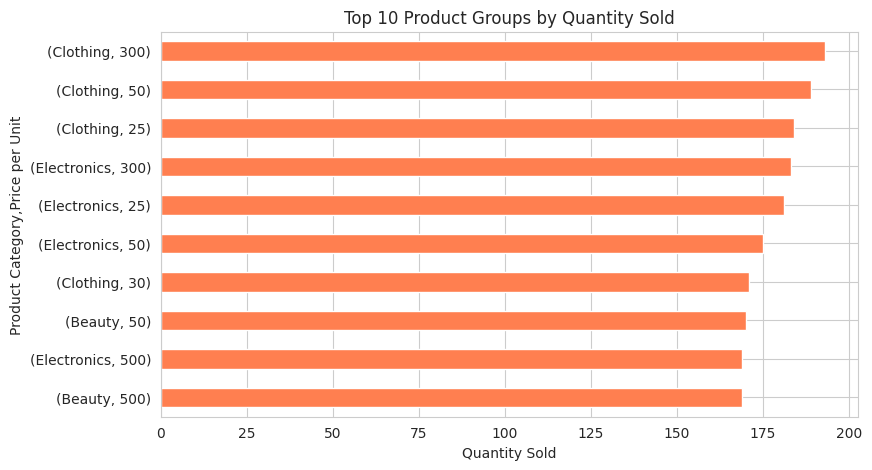

In [ ]:
# 1. Revenue by product category
category_revenue = df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=category_revenue.index, y=category_revenue.values, palette="Set2")
plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.show()

print(category_revenue)

# 2. Units sold by category (this dataset has only 3 categories,
#    so we show the top "products" by quantity sold per category and price)
top_products = (df.groupby(["Product Category", "Price per Unit"])["Quantity"]
                  .sum()
                  .sort_values(ascending=False)
                  .head(10))

print("\nTop 10 product groups by quantity sold:")
print(top_products)

top_products.plot(kind="barh", figsize=(9, 5), color="coral")
plt.title("Top 10 Product Groups by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.gca().invert_yaxis()
plt.show()

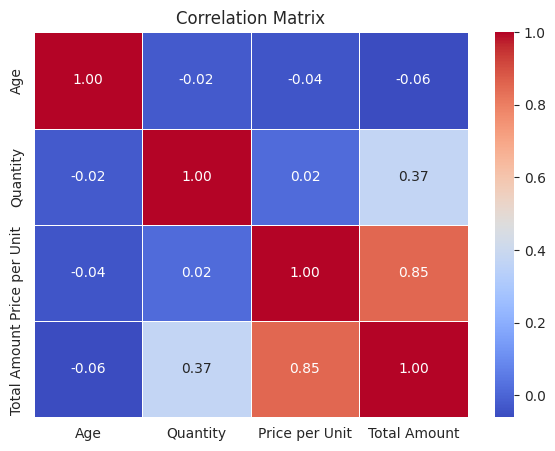

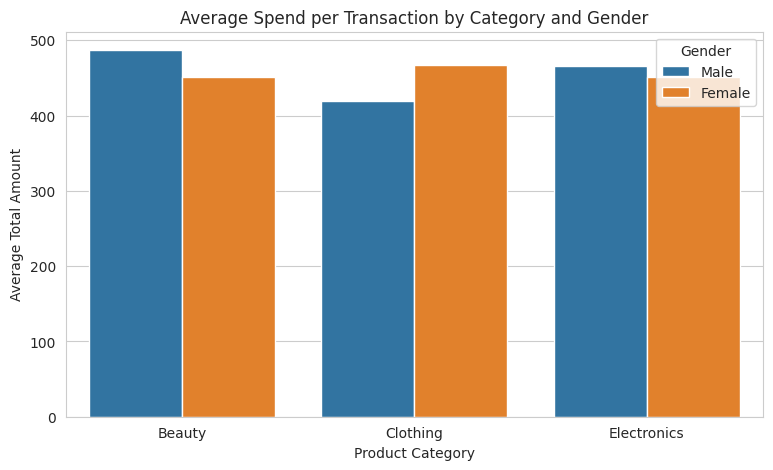

/tmp/ipykernel_539/138919685.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=weekday_sales.index, y=weekday_sales.values, palette="mako")


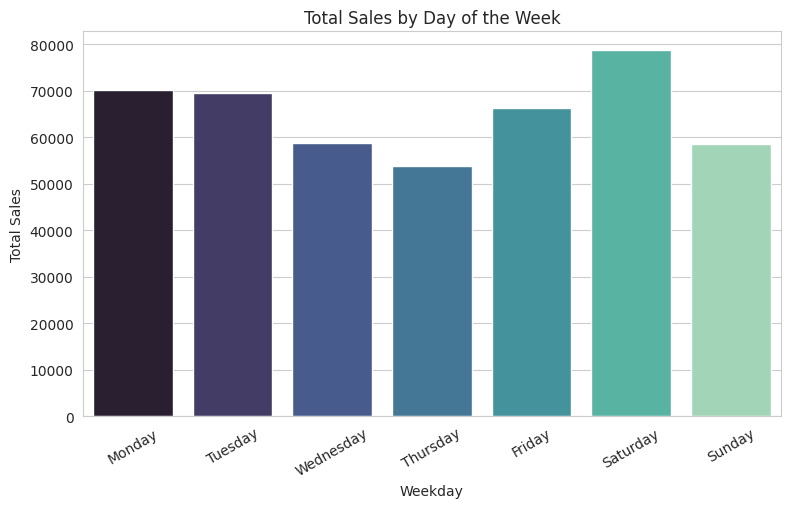

                     Age  Quantity  Price per Unit  Total Amount
Age             1.000000 -0.023737       -0.038423     -0.060568
Quantity       -0.023737  1.000000        0.017501      0.373707
Price per Unit -0.038423  0.017501        1.000000      0.851925
Total Amount   -0.060568  0.373707        0.851925      1.000000
Weekday
Monday       70250
Tuesday      69440
Wednesday    58770
Thursday     53835
Friday       66290
Saturday     78815
Sunday       58600
Name: Total Amount, dtype: int64


In [ ]:
# 1. Correlation heatmap (numeric columns only)
corr_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]

plt.figure(figsize=(7, 5))
sns.heatmap(df[corr_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix")
plt.show()

# 2. Extra insight: average spend per transaction by category and gender
plt.figure(figsize=(9, 5))
sns.barplot(x="Product Category", y="Total Amount", hue="Gender", data=df, errorbar=None)
plt.title("Average Spend per Transaction by Category and Gender")
plt.ylabel("Average Total Amount")
plt.show()

# 3. Extra insight: sales by day of the week
df["Weekday"] = df["Date"].dt.day_name()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_sales = df.groupby("Weekday")["Total Amount"].sum().reindex(order)

plt.figure(figsize=(9, 5))
sns.barplot(x=weekday_sales.index, y=weekday_sales.values, palette="mako")
plt.title("Total Sales by Day of the Week")
plt.ylabel("Total Sales")
plt.xticks(rotation=30)
plt.show()

print(df[corr_cols].corr())
print(weekday_sales)

In [ ]:
# Key numbers for the conclusion
print("Total revenue:", df["Total Amount"].sum())
print("Average transaction value:", round(df["Total Amount"].mean(), 2))

print("\nRevenue by category:")
print(df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False))

print("\nRevenue by gender:")
print(df.groupby("Gender")["Total Amount"].sum())

# Age groups
df["Age Group"] = pd.cut(df["Age"], bins=[17, 25, 35, 45, 55, 100],
                         labels=["18-25", "26-35", "36-45", "46-55", "56+"])
print("\nRevenue by age group:")
print(df.groupby("Age Group", observed=True)["Total Amount"].sum())

# Monthly trend
df["Month"] = df["Date"].dt.to_period("M")
print("\nMonthly revenue:")
print(df.groupby("Month")["Total Amount"].sum())

Total revenue: 456000
Average transaction value: 456.0

Revenue by category:
Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

Revenue by gender:
Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64

Revenue by age group:
Age Group
18-25     84550
26-35     98480
36-45     91870
46-55    100690
56+       80410
Name: Total Amount, dtype: int64

Monthly revenue:
Month
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64


In [ ]:
# Full monthly revenue
print("Monthly revenue:")
print(df.groupby("Month")["Total Amount"].sum().to_string())

# Correlations
corr_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]
print("\nCorrelation matrix:")
print(df[corr_cols].corr().round(2))

# Weekday sales
df["Weekday"] = df["Date"].dt.day_name()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
print("\nSales by weekday:")
print(df.groupby("Weekday")["Total Amount"].sum().reindex(order).to_string())

# Clothing: average spend by gender
print("\nClothing, average spend by gender:")
print(df[df["Product Category"] == "Clothing"].groupby("Gender")["Total Amount"].mean().round(2))

Monthly revenue:
Month
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M

Correlation matrix:
                 Age  Quantity  Price per Unit  Total Amount
Age             1.00     -0.02           -0.04         -0.06
Quantity       -0.02      1.00            0.02          0.37
Price per Unit -0.04      0.02            1.00          0.85
Total Amount   -0.06      0.37            0.85          1.00

Sales by weekday:
Weekday
Monday       70250
Tuesday      69440
Wednesday    58770
Thursday     53835
Friday       66290
Saturday     78815
Sunday       58600

Clothing, average spend by gender:
Gender
Female    467.1
Male      419.8
Name: Total Amount, dtype: float64


## Conclusion

### Key Findings

1. **Overall performance:** Total revenue is 456,000 with an average transaction value of 456.
2. **Categories are closely balanced:** Electronics leads (156,905, about 34.4%), Clothing is a close second (155,580, about 34.1%), and Beauty is lowest (143,515, about 31.5%).
3. **Gender:** Female customers contribute slightly more revenue (232,840) than male customers (223,160), a gap of about 2 percentage points.
4. **Age:** The 46-55 group generates the most revenue (100,690), followed by 26-35 (98,480). The 56+ group generates the least (80,410).
5. **Monthly trend:** May is the peak month (53,150) and September is the weakest full month (23,620). October (46,580) and December (44,690) are also strong. January 2024 is a partial month and is excluded from this comparison.
6. **Correlation:** Price per Unit has the strongest correlation with Total Amount (0.85), followed by Quantity (0.37). This makes sense because Total Amount = Quantity × Price per Unit. Age has almost no correlation with spending (-0.06), so age alone does not predict how much a customer spends.
7. **Weekday:** Saturday is the best sales day (78,815) and Thursday is the weakest (53,835).
8. **Clothing by gender:** Female customers spend an average of 467.1 per Clothing transaction, versus MALE_VALUE for male customers, so 419.8 customers spend more.

### Business Recommendations

1. **Strengthen Beauty.** It trails the other categories by about 12,000 to 13,000. Bundle it with Clothing and Electronics purchases and run targeted promotions.
2. **Plan around seasonality.** Sales peak in May, October and December, and dip in March and September. Stock up before the peaks and run discount campaigns in the weak months.
3. **Lift Thursdays.** Thursday sales are about 32% below Saturday, so offer mid-week deals to bring in more customers.
4. **Target the 26-55 age range.** These groups bring in the most revenue. Use engagement offers to grow the 18-25 and 56+ groups.